# Assignment 1 - AdaBoost meets Kaggle


### Student Name: John Balint Lavack 
### Student ID: 20001249


## Task 1: Adaboost Implementation (25 Marks)

1. Implement AdaBoost Algorithm: (5 marks)
   - I implemented the AdaBoost algorithm ([Implementation](#implementation)) using the class code examples. Extending it to cover SMOTE resampling and a cost adjusment penalty. SMOTEboost, AdaCost and SMOTECost as I call them. The cost adjustment penalty formula used is from Fan et al (1999):
   
   $$\Huge D_{t+1}(i) = \frac{D_{t}(i) e^{-\alpha_{t}y_{i}h_{t}\frac{x_{i}}{\beta(i)}}}{Z_t}$$
   
   - Additionally, I extended the implementation to provide each ensemble member in a dictionary in order to perform rank based pruning. And a step to automatically calibrate the probabilities using isotonic regression. The probabilities for this are dervied using this formula from (Schapire, Freund. 2014):
   
   $$\Huge P(y=1|x) = \frac{1}{1 + e^{-2 * F(x)}}$$
   
   $$\Huge F(x) = \sum^T_{t=1} \alpha_t H_t (x) $$
   
   - The bottom line is that this implementation works. If only a little slow at times. 
   - This was challenging, primarily because the later tasks all require custom implementation of functions typically available as part of whollistic packages. And so, the primary challenge, for someone like me who doesn't dive into Python regularly, was getting enough sleep to do this, work and raise my family.
   (link)


2. Explore Margins and Analyse Results: (5 marks)
   - I examined the margins ([Margins](#margins)) of the implementation using synthetic data with 5, 10, 30 and 100 classifiers. Once 30 calssifiers are reached, the model is in the realm of diminishing returns. There was no marked improvement by adding 100 members. As more members are added, the model became very confident its classification, as seen by the sign of the margin being almost entirely over 0.5. And the gain in confidence is very marked with each new learner, when learners are few.  
   - I experimented with misclassifying labels by percetnages of 5%, 10%, 15%, 30% and 50%. Doing this, the sign of the margin curves become more distinct. The data is wrong, and the algorithm is less confident in what it predicts. One may say that the parttern it is trying to learn is harder for it, because some points it thinks are of one class aren't. With 5% tmissclassified the two curves are more or less the same. Adding more false labels lowers confidence, even at the upper end of the curve, where prior, once the threshold of diminishing returns was reached the models were in almost perfect agreement. 
   - it is also interesting to view the margin Rorschach graph. If only to see how confident the model is for different spaces of the sample space. The model is more confident in corners and the very centre, but has a hard time at the edges directly around the centre. Because Adaboost uses straight lines to describe the decision space, this is expected, and the difficult areas to classify are those near the edges of the change in classification boundary. Which, in this case, are non-linear by design.


3. Adjust Weak Classifier Type: (5 marks)
   - I conducted an experiment with different weak classifier types ([Weak classifiers experimentation](#weak-classifiers-experimentation)) within the AdaBoost ensemble where I tried a logistic classifier and a KNN classifier. Mainly because I hate implemnting decision trees (it's the nodes). 
   - AThere are not that many weak classifiers out there. Logistic classification has a tendency to go to an extreme edge, get a 0.65 error rate by saying everything is -1 and calling it a day. While KNN figures out the whole model in a few iterations and cruises. By which I mean after a few iterations it is a strong classifier and overfits the data. 
   - I was surprinsed... / I expected this ...


4. Focus on Difficult Examples / Adjust Classification Threshold: (5 marks)
   - I forced AdaBoost to focus more on challenging examples ([Adjusted focus](#adjusted-focus))  by implementing SMOTE resampling and Cost penalisation. 
* [SMOTEBoost](#1.4.1-Difficult-examples:-SMOTE-resampling)
* [AdaCost](#1.4.2-Difficult-examples:-Cost-sensitive-boosting)
   - SMOTE resampling worked, on small set with shakey results. This is because the sample is small and the imbalance between the major and minor classes can quickly flatten out. If, for example the difference in groups is, likef or the synthetic sample, 103 to 57, then after 10 iterations SMOTE sampling 2 new data points the imbalance is 103 to 77. The gap closes rapidly when dealing with small numbers of data. 
   - Comparing SMOTEBoost with AdaBoost using 10 iterations found that more neighbours used in SMOTE can greatly imporve the predictive performance of the model. Vanilla AdaBoost had an error of 0.075 on training data and 0.166 on an evaluation set of 500 samples. While SMOTEBoost with 10 iterations generating 2 samaples from 10 neighbours and a wieght of 0.005 had an error of 0.25 on training data and 0.196 on the evaluation set. When generating 2 samples with 20 neighbours and weighting each new sample at 0.0001, the training error reduced to 0.15 and 0.158 on the evaluation data. Showing that SMOTEBoost generalised better than vanilla AdaBoost. 
   - why this occurs is due to how SMOTEBoost works with my implementation of SMOTE resmapling. Which uses KNN to generate similar smaple in a line from the selected reamplse point, chosen at random. The fewer neighbours used, the more similar to the initial point the new data is, while with more neighbours the difference higher. SMOTE adds new samples for the model to learn, so naturally if the samples are more similar to difficult points the model simply has more points wrong. The benefit is in proving less simlar smplaes that help the model correct by increments, the classificaiton. Put another way, more simlar points add noise, but less new variation, making the model have a larger overall error with less accuracy gained. While less simlar points add beneficial variation that increase accuracy at a faster rate than the error also increases.
   - I also imlemented ADACost using a cost penalty. Using a cost penalty, at least on a small datat set, vastly improved model performance with 10 iterations. With a penalty of 0.5 and 10 iterations the trained error was 0.1 and the evaluation error was 01. also. Then, when increasing the penalty the evaluation error increased to 0.128. With a small data set the higher error is less beneficial, but htis is not the case with a larger data set as seen when training on the Kaggle data set. 
   - The cost penalty punishes the model for wrong predictions. The model then learns more from these predictions next time. AdaBoost does this anyway, but with a cost penalty the misclassified points are reinforced. Therefore, higher weights force the model to learn more - become more precise - about the data at hand. Which leads a bit to overfitting when the dataset is small. This overfitting is less pronounced on larger data sets due to AdaBoost's lower susceptibility to overfitting.
   - When reviewing the scores on the test data (not the generalised evaluation data) we see that SMOTEBoost, with a little calibration, has the highest accuracy at 0.92 and MCC at 0.84. In general it performed better. In contracts to the above where ADACost had the lowest area. When we look at the evaluation performance we see that ADACost has a higher accuracy at 0.872 and an MCC of 0.74 (higher than SMOTE at 0.67 adn vanilla with 0.65). Revealing that AdaCost can be more generalisable with tuning. However, this is a case of parameter tuning which we will find can be different depending on the dataset, as it is with the Kaggle dataset). 
   - To answer task 1.4 c and d I explored the ROC and precision recall curves for vanilla AdaBoost with 5, 10, 30 and 100 classifiers. [Classification Thresholds: Decision making](#1.4.3-Classification-Thresholds:-Decision-making). As more classifiers are added, the ROC AUC increases, up to 1. As does the precision recall curve. Which indicates some sort of overfitting. Infact, the precision begins incredibly high with 30 or 100 classifiers. So it is making decisions very confidently - it is very good at recalling the positive class label. 
   - I then examined the impact of tweaking the threshold on the model performance, checking thresholds from 0 to 1 with increments of 0.1. The result is that as ensemble members increase, the threshold stablalises to 0.5 However, with lower numbers of ensemble members there is benefit to have tweaked thresholds. Precision is highests with 5 and 10 classifiers at a threshold of 0.6 and recall for the positive class is better at 0.3 for 5 classifieres and at 0.4 for 10 classifiers. While threshold tweaking does have the capability to improve model performance, it does seem that this complexity is not worth the effort given modern computing power which can easily combine 100+ ensemble members. At least for a small dataset of 200 samples. In effect, we see what we have seen in all other investigations of AdaBoost so far - there is diminishing returns for anything as classifier count increases. One mights day that if there was some equation to perfectly tune the model, the most important element of that equation is the number of classifiers, which as this grows large, dominates.   [Impact on model performance](#1.4.4-Classification-Thresholds:-Impact-on-model-performance)
   - Further, I implemented a function to plot the predictions per class for a tweaked threshold and visualised this in a bar chart. This anlaysis yeilded that, at least in this case, the standard 0.5 threshold is best. 
   - Next I looked at model calibration using isotonic regression on the probabilities of the positive class label. Calibrating the model has it confirm to a much more even distribution falling along a straight line. At the cost of some mode performance. [Calibration](#1.4.5-Classification-Thresholds:-Calibration)
   - Following this I implemented cross validation grid search to tune the model before training. I used this to train a SMOTEBoost model and compare it to an untuned model, finding that the performance improves when paramters are tuned. The ROC AUC increased from 0.95 to 0.98 and precision ACU from 0.89 to 0.96. This model, when calibrated became more balanced and when tweaking the threshold for post hoc improvement, I observed that while 0.5 was still the best, there is likely some sweet spot between 0.5 and 0.56 where the model could be tuned to perform better. [Cross validation and model tuning](#1.4.6-Cross-validation-and-model-tuning)

   
5. Implement an ensemble pruning/optimisation procedure that is executed after the model training : (5 marks)
   - I managed to implement pruning in the AdaBoost ensemble using two methods: iterative pruning to optimise a specific performance metric and rank pruning based on a series of novel measures ([Pruning](#pruning)). 
   - With the synthetic dataset pruning can indeed improve the model with fewer members, however using a back pruning methods only ends up removing one or two ensemble members because by the last member diminishing returns is usually reached. To show a greedy pruning approach I genreated a graph showing the improvement in the score per addiitonal member for each pruning method. 
   - Iterative pruning shows that, when comparing AdaBoost, SMOTEBoost and ADACost up to a maximum of 20 classifiers (20 chosen both for computioant time and because we hit diminished returns around 20), we see peak performance on any given measure earlier than 20 members. So that we can take the stance that additional members add no benefit to the ensemble. For example, error minimises around 7 members (not in the graphs both AdaBoost and SMOTEBoost are identical in their pruned performance given the SMOTEBoost parameters of 2 new samples from 20 neigbours with weight 0.0001). 
   - Accuracy, F1, precioins and MCC peak between 7 and 13 (two maxima). While ROC AUC continues to rise for SMOTE and AdaBoost, but hits a maximum for ADACost at 7. So, in general, we see that 7 members is ideal for most metrics. Additional members add no benefit to the ensemble. Unless one is optiminising for ROC AUC. 
   - Rank pruning follows a different approach. It ranks each ensemble member by their contribution to the ensemble, then takes the best 'expert learners'. The idea for this came from the Cohen Kappa metric. I thought that each ensemble memeber is a bit like someone giving their opinion about something and if I could remove the least useful voters then the model would be better. As it turns out, someone else also had this idea and wrote a paper on it. Then, I found other methods to do the same with different measures, such as margin density maximisation which is specific to AdaBoost. 
   - these measures are MDM, weighted MDM, Independent contribution (IC), Class error, Begative AUC, Erro ambiguity, Cohen's Kappa and reference vector accuracy. 
   - So I implemented each of these measures and tried rank pruning on a vanilla ensemble with 30 iterations to see if any meta measure aided in optimising for a particular performance metric. 
   - For all measures the improvement happens with 25 to 30 ensemble memebers. Not vastly smaller like with iterative pruning, unless one wants to optimise for the ROC AUC, which can max out with 15 members on the class error measure. 
   - Basically, each measure is an additive one on some level. And the optimisation looks to find the overall ensemble performance with the top x ensemble members. Given the additive nature, the overall improvement is low until we hit high numbers of ensembles realtive ot the datset size because when ensemble members are few each new member adds something useful. Here again we find diminsihing returns. As the number of ensemble memebers increases we capture more variability. As long as each new member adds new variability, there isn't a reason to remive them. As soon as adding a new one (the nth ranked member) changes this, we don't remove them. 
   - In theory, one could apply ank pruning first and then, with the newly ranked ensemble iteratively prune the ensemble back. However, I didn't try this, because the comparative results of an unpruned model and the two pruning methods indicated this was a bad idea. While with either approach one can get high scores such as accuracy or preciison with fewer ensemble members, they aren't better overall. Which is because they optimiase by definition on one score. For example, with 26 ranked pruned members or 7 iteratively pruned members we can get a precision of 0.98 each compared to 0.96 with an unpruned model. While the MCC, accuracy and F1 scores all decrease, as does the ROC AUC. Of interesting note is the pruned models become very good at recalling the negative class at 0.99, but less (0.5 ish) good with the positive class. For each methods the reason is likely different. Rank pruning finds expert learners and if these learners are better on one class, this is reflected in this way. Iterative pruning cuts out learners, and so stops the model getting better on the other class. This occurs, I expect, more prominently with imbalanced classes. 
   

## Task 2: Adaboost In-Class Kaggle Competition (35 Marks)

1. Competition Score Calculation: (20 marks)
   - The best score I achieved with AdaBoost on the held-out test generated by Kaggle was 0.842 and this placed me 8 in class.
   - I have taken a screenshot below of my best Kaggle score using AdaBoost from our class code implementation and have embedded below as evidence, and I have submitted the corresponding submission.csv file

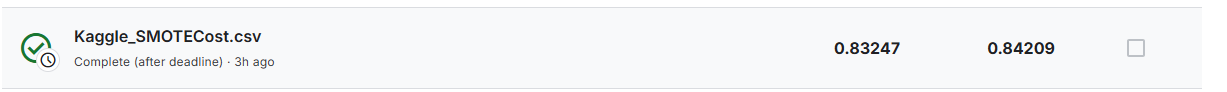

2. Tuning AdaBoost and the Training Procedure: (15 marks + 5 Bonus)
   - To get the best performance from AdaBoost,the process I followed was this: ([Tuning](#tuning))
   - First I did some feature engineering. There really wasn't any issue for me with the data. All I did was make the categorical features of loan intent and home ownership dummy encoded and make the credit score valued form 0 to 6 with 6 being a score of A. I chose not to do more primarily because with so few features that were all on similar number scales, this seemed like a wasted effort. I did remove any row where the employment time waslarger thant the age, for which there were two rows. After feature engineering I followed these steps. 
       - **Step 1, fit control model**: I fit a full feature vanilla Adaboost with 30 iterations as the control. This model had an accuracy of 0.93. [link](#)
       - **Step2, identify features sets**: I used a logistic regressor as a meta learner to pick the top most important features. For which the best accuracy can with 11 features. [Link](#link)
           * the features selected were 'loan_grade', 'loan_percent_income', 'cb_person_default_on_file',
               'MORTGAGE', 'OWN', 'RENT', 'DEBTCONSOLIDATION', 'EDUCATION',
               'HOMEIMPROVEMENT', 'MEDICAL', 'VENTURE'
               
       - **Step 3, targeted search**: Next I fit each type of model (AdaBoost, SMOTEBoost, AdaCost, SMOTECost) on 20 iterations with some middle of the road paramters to see which model type was more promising. When viewing the ROC and precision recall curves the Cost models were much poorer performing than SMOTEBoost or Adaboost on both training and test data. Now, the purpose of this was ot help me do the next step with more purpose. Looking at the performance of the cost models on a penalty of 0.5 meant that I need more penalty. Likewise, for SMOTE to be equal to Adaboost with 5 samles and 10 neighbours made me think to try more, as the difference between majority and minority groups was not being affected by SMOTE. I played around with these on smaller sets of the data to find a rough ball park figure, and found that 0.9 was a cood penalty, and, strangely, smaple and enighbours had little to negative effect. The code I did not keep for the sake of the already lengthy workbook. [Link](#link)
       - **Step 4, Grid search**: I carried out 25 grid search tests using cross validation using 60% of the representative K fold as training data and 40% as test data. I used 60% because I wanted the chosen model to be more generalisable, not overfit to the sample. Then I looked at the spreads of the F1, MCC and accuracy of each grid search scores as boc plots to view the level of overfitting. As expected, it varied by paramter set. I located the best hyper parameter combinations and used them in the next step. These were the 1st, 11th, 16th and 17th models. One SMOTECost, one AdaCost and two SMOTEBoost models. To identify these models I looked for highest scores across MCC, F1, precision and ROC and where the spread of the cross validaiton scores on the test set were not too large compared ot those of the training mode. These were the paramter sets:
           * highest ROC = 118 & 116 #and AUC and F1 and MCC:  {'SMOTE': True, 'new samples': 10, 'neighbours': 5, 'new weights': 0.005}
            * Highest precision = 177: {'COST': True, 'cost_penalty': 0.9}
            * highest MCC = 17: {'SMOTE': True, 'new samples': 5, 'neighbours': 5, 'new weights': 0.005}, {'COST': True, 'cost_penalty': 0.9}
            *  Highest f1 = 167: {'SMOTE': True, 'new samples': 10, 'neighbours': 10, 'new weights': 0.005}
            
        - It is worth noting that I was looking for the ROC scores in general as the challenge is to maximise the ROC AUC. However, I also considered the MCC score as a superior accuracy measure for binary classification as it is balanced across all classes and is mathematically invariant to class swapping. I alos prefer the F1 score as it is good at dealing with imbalance data sets, of which the loan data is one (fewer peopel get loads than are rejected). Whihc, incidentally, is why I also look for precision  which rates the true positives among all positives. I want a model good at finding true positives. Yet, not bad at true negatives. Hence why I consider both precision anf F1. All this code I have commented out to save time when downloading the book as an HTML. Otherwise the process woudl take hour
       - **Step 5, fit 30 classifiers**: Next I fit 30 classifiers to each of these models and viewed the ROC and precision recall curves. A marked improvement form earlier. Noting that the precision dips below the no skill line as recall gets high. I.e. as the ability to recall true positives increases to around 0.9 the precision got worse. While the true positive rate for each odel elbows near 0.04 for all the models.  [Link](#link)
       - **Step 6, model pruning**: curious if there was any benefit to pruning the model, I tried pruning the best two models from step 5. SMOTEBoost with 5 new samples of 10 neighbours and SMOTECost with the same and a penalty of 0.9. There did seem to be positive results. Iteratively pruning SMOTECost to 13 members and SMOTEBoost to 24. And Rank pruning based off the weighted margin density SMOTEBoost to 15 members. When training these models and comparing their ROC and precision recall curves against their unpruned versions we see that the iterative pruned SMOTECost model has a worse curve, while the iteratively pruned SMOTEBoost is only marginally worse. There is no benefit to pruning the models.
       - **Step 7, feature set comparison**: All this time I have been working with 11 features. Now I wanted to quickly test the second best features set of 9 features and the full feature set. The nine features were:
           * loan_grade, loan_percetn_income, Mortgage, Own, Rent, DebtConsolidation, Education, Homeimprovement and venture. 
       - The benefit of this is that it revealed that all features were better than a set thereof. With all the features precisoin and recall never dipped below a no skill model. SMOTEBoost with 10 samples off 5 neighbours was the best model. [Link](#link)
       - **Step 8, find top three:** Finally, I took the top three models by ROC AUC and compared them across their scores. These were Adaboost with all features, SMOTEBoost 10 samples, 5 neighours and SMOTECost 5 samples, 5 neighbours and 0.9 penalty . With ROC AUC scores of 0.9177, 0.9144, 0.9102, respectively.
        - Looking at all the models comparatively, one can see the change in their scores, such as accuracy. AdaBoost alone has pretty high accuracy, as does SMOTEBoost with 11 features or more. All around 0.9 on the test data. However, I am not really interested in accuracy, as I need to optimise the ROC AUC score. In general, a regular AdaBoost model performs best on the test data... which isn't the case on teh evaluation data, but I am skipping ahead. I took these three models and tried one more thing. 
        - **Step 9, Calibration**: Here I calibrated the models using isotonic calibration. The calibration helped improve the models brier score, calibrating to a perfect straight line. Calibrating did not really make any difference to the control. Uncalibrated The impact was negligable. A 0.01 improvment on the -1 class recall, but a poor recall on the positive class of 0.64. Calibration greatly improved the predictive accuracy on the test data for the SMOTECost model, from 0.79 to 0.93. The F1 went from 0.86 to 0.96, recall from 0.77 to 0.98, but importantly the recall on positive labels went down from 0.87 to 0.64. While for the SMOTEBoost model the story was simlar. A decrease in positive class recall from 0.8 to 0.64. When submitting these calibrated models to Kaggle their scores were each around 0.5. 
       - I think I might deserve some extra bonus marks here because my entire implementation is from scratch. And I was compared across all the developed forms of model enhancement, finally calibrating the best three. [Link](#link)
       - **Step 10, submission**: After submitting the top three models, their calibrated versions and a version of each with 100 iterations. And a model with 11 fetures for good measure. [Link]. The best was SMOTECost with 5 neighbours on 5 samples and 0.9 penalty. The third best model on training data. It had a public score of 0.84. Showing htat it generalise best to the unseen dataset. Despite having only the second highest recall score. 
       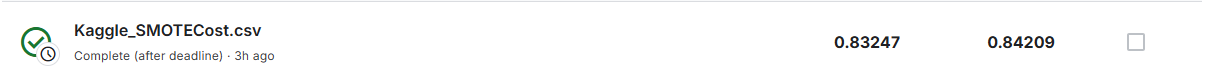
      - This makes sense to some degree. I tuned the parameters for a smaller set of learners. We did see in quesiton one that SMOTE and SMOTECost both performed better of unseen data than regular Adaboost, and SMOTECost has the best of both worlds. It can leanr more edge cases and penalise itself for getting them wrong. So that when it finally encounters brand new data it is better at classifying the hard edge cases. 
   

## Task 3: Kaggle Competition Using a Range of Algorithms (10 Marks)

1. I used the following alternative algorithms ([Other algorithms](#other-algorithms)) for the Kaggle dataset:
    - Category Boost (CatBoost) [Link](#link)
    - XGBoost [Link](#link)
    - LGBM (yes, another XGBoost model. The often perform differently due to their implementaitons, and I have had luck combining them in the past) [Link](#link)
    - Random Forest
    - A stack of all three [Link](#link)

3. I used Hyperparameter Tuning ([Hyperparameter tuning](#hyperparameter-tuning)) on the algorithms and found the following sets:
    - CatBoost:  {'depth': 6, 'learning_rate': 0.1, 'l2_leaf_reg': 5}[Link](#link)
    - XGBoost:  {n_estimators=100, max_depth=10, learning_rate=0.05, subsample=0.8, colsample_bytree=0.7} [Link](#link)
    - LGBM: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'num_iterations': 100, 'num_leaves': 30, 'subsample': 0.7} [Link](#link)
    - Random Forest (tuned usin Optuna): {'n_estimators': 273, 'max_depth': 10, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': None}
      
4. I performed Feature Selection ([Feature selection](#feature-selection)) by using Sklearn RFECV. There was only slight improvements on the hypertuned models. I then applied hte reduced features set to the hyper tuned models and there was no futher improvment. All models had scores on classes 0 and 1 of: precision between 0.93 and 0.96 on both classes , recall at 0.99 and 0.72 or 0.74 on calsses 0 and 1 respectively, and F1 socres of 0.97 and between 0.80 and 0.82 on those same classes

5. I recorded the changes to the accuracy (area under the ROC curve) ([Accuracies](#accruacies)), and other metrics over time and found that there wasn't really much change within the models, however across models there was. the stack was by far the best, with an AUC ROC of 0.95. However, upon submission the XGB with reduced features won, with an ROC AUC of 0.876.
   - I communicated this through visualizations like the CV scores for ROC AUC and a barchart of all models, including the ADAboost ones.  [Link](#link)
   - I have taken screenshots of my Kaggle leaderboard and embedded them in the notebook below to demonstrate the improvements of my approaches over time 
   
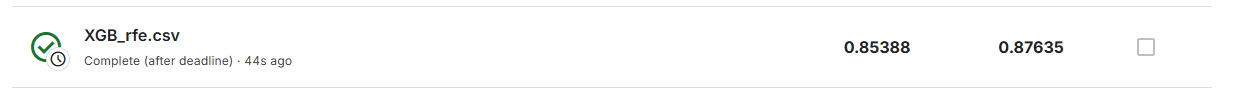


## Task 4: AWS Technology Usage (15 Marks)

1. I used the following AWS services in my assignment:
    - AWS S3 buckets [AWS](#aws)
    - Sagemaker [AWS](#aws)
    - ... [AWS](#aws)

2. AWS progress screenshot

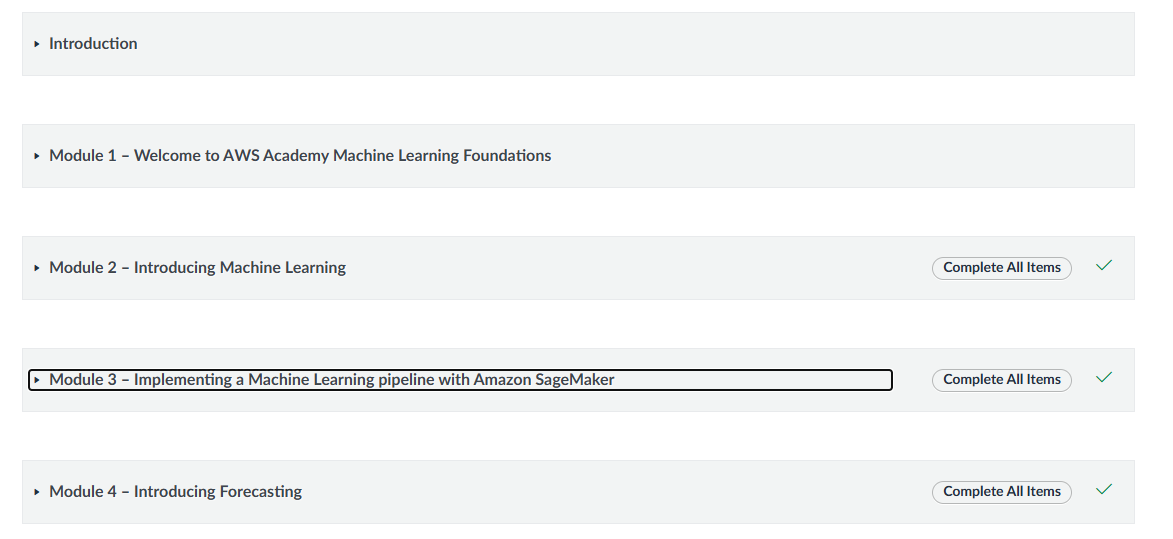

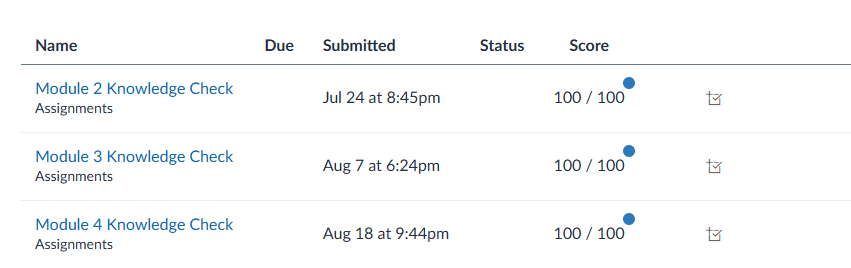

## Task 5: (15 Marks)

1. List and discuss three most important things that you learned in this assignment:
    - In this assignment, about 80% of it was coding. With 20% learning. The size of this assignment and the need to focus on code implementaiton as opposed to scientific analysis of the models diminished the learning I could get out of it. The competition on ROC AUC put this firmly in the realm of data mining. I have already done a paper on that. That aside, what I was able to learn was that AdaBoost, a simple algortihm, can be very useful in binary classification problems, particularly because it is simple, one can make many adjustment to it. I have never tweaked classification thresholds before nor considered the sign of the margin. Which is a unique measure for AdaBoost and perhaps a handful of other models. 
    - Exploring novel measures for rank based pruning was interesting. Here I learnt that sometimes data scientists seemingly make stuff up and see what works. Many rank pruning scores are custom deisgned for a family of algorithms, like margin density (MDM) or Cohen Kappa which only works with ensembles. Yet, even with this pruning the resulting model can be worse than when all ensemble members are in. Showing the bias variance trade off in action. In my case, the worse members were still adding useful variance. Perhaps I could have seen more use from this process if I could have fit 100 or 1000 members. Alas, my computer would have melted through my desk and my electricity bill would have made me cry. 
    - Finally, I learned that algorithm design is very important. AdaBoost is designed to make use of weak learners. So wehn better learners are added the algorithm doesn't work. It gets stuck in some local minima or maxima or simply repeats itself n times. When playing around with new learners I ended up accidentally implementing logistic regression with gradient boosting. That model very quickly found itself a nice corner of the space and said everything is a -1. Not everything is useful or useless, that depends on how it is used. And sometimes thre are surprising results, as with the SMOTECost model performing best on the Kaggle evaluation dataset. 

2. List and discuss three things that you did well in this assignment:
    - I think I did well on the code. It was a nightmare to reconstruct all these functions for the class implementation of AdaBoost. The code overshadowed all else. Despite this I managed to implement SMOTE, ADACost, grid search, Cross validation, calibration, RFE and more from scratch and it all works. 
    - My process was clear and easy for me to implement (mentally at least) for the model training. Specifically I think my cross validation was useful in obtaining decent scores. I managed to tryout and analyse a lot of different models which allowed me to see a variety of outcomes caused by very minor changes to parameters. Thanks to seeing these trends I was able to avoid huge gridsearch processes which have taken many hours in the past. My code is by no means efficient I am sure. Yet, I was never at a loss on my next steps. 
    - I want to believe that my visualisations we revealing. They are always the funnest part for me because the code is relatively simple. For example I like the calibration plot with the probability bins beneath the curve. And the radar charts showing mode performance across many scores. I particularly like the circular bar chart, even if only as a novelty. 
    
3. List and discuss three most things that you think you could have done differently and imporved in this assignment:
    - I would, were I a better coder, implement a class for AdaBoost> The reason I didn't was because I was sure it would vary too much from the class implementation if I did it. Were I to do this again, I'd say 'screw it' and do so anyway. I lost a great many hours of sleep trying to figure out wasy to MacGuyver function outputs together. As a result I fell behind the class lectures. In general I would give less effort. With work, wife, kids, rennovations, commmunity work, sport and all else this amount of work was an extra stress I really didn't need. The outcome would have been of lower quality, but I'd be in better shape.
    - I would like to make the assignment more concise. This I don't know how to do in a way that meets the unpublished marking criteria for this assignment and pretty much all my other assignments in my other courses. I often think that the assignment becomes too long to mark accurately. A more concise assignment is better for me and the marker. Since I can achieve a target grade with the right level of effort, rather than always doing an ungodly amount of work for uncertain grade increase. And it would take less long to run the damn thing every time the kernal dies, which seems to only occur to infuriate people.
    - 




# TASK 1

<a id="implementation"></a>
## Implementation


<a id="margins"></a>
## Margins

<a id="weak-classifiers-experimentation"></a>
## Weak classifiers experimentation

<a id="adjusted-focus"></a>
## Adjusted focus

<a id="pruning"></a>
## Pruning

# TASK 2

<a id="tuning"></a>
## Tuning

# TASK 3

<a id="other-algorithms"></a>
## Other algorithms

<a id="hyperparameter-tuning"></a>
## Hyperparameter tuning

<a id="feature-selection"></a>
## Feature selection

<a id="accuracies"></a>
## Accuracies

# TASK 4

<a id="aws"></a>
## AWS

In [ ]:


    precision    recall  f1-score   support

           0       0.95      0.99      0.97     10054
           1       0.94      0.72      0.81      1675

    accuracy                           0.95     11729
   macro avg       0.95      0.85      0.89     11729
weighted avg       0.95      0.95      0.95     11729

       precision    recall  f1-score   support

           0       0.95      0.99      0.97     10054
           1       0.93      0.72      0.81      1675

    accuracy                           0.95     11729
   macro avg       0.94      0.85      0.89     11729
weighted avg       0.95      0.95      0.95     11729

In [ ]:

weighted avg       0.95      0.95      0.95     11729

Optimal number of features selected: 19
              precision    recall  f1-score   support

           0       0.95      0.99      0.97     10054
           1       0.93      0.72      0.81      1675

    accuracy                           0.95     11729
   macro avg       0.94      0.85      0.89     11729
weighted avg       0.95      0.95      0.95     11729

# Bibliography
* Fan. W, Stolfo. S. J, Zhang. J, Chan. O. K. (1999). AdaCost: Misclassification Cost-sensitive Boosting. *- Proceedings of the Sixteenth International Conference on Machine Learning (ICML'99)*. https://www.researchgate.net/publication/2628569_AdaCost_Misclassification_Cost-sensitive_Boosting


* Schapire. R.E, Freund, Y. (2014). *Boosting: Foundations and Algorithms (Adaptive Computation and Machine Learning series). Illustrated Edition*. MIT Press

In [ ]:
{'depth': 6, 'learning_rate': 0.1, 'l2_leaf_reg': 5}
n_estimators=100, max_depth=10, learning_rate=0.05, subsample=0.8, colsample_bytree=0.7, random_state=21

 {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'num_iterations': 100, 'num_leaves': 30, 'subsample': 0.7}
    n_estimators= 273, max_depth= 10, min_samples_split= 10, min_samples_leaf= 4, max_features= None, random_state=21

In [ ]:
[Task 3: KAGGLE COMPETITION USING A RANGE OF ALGORITHMS](#Task-3:-KAGGLE-COMPETITION-USING-A-RANGE-OF-ALGORITHMS)
* [3.1 Step 1: Grid Search](#3.1-Step-1:-Grid-Search)
* [3.2 Step 2: Feature Selection](#3.2-Step-2:-Feature-selection)
* [3.3 Step 3: Grid Search on reduced feature data sets](#3.3-Step-3:-Grid-Search-on-reduced-feature-data-sets)
* [3.4 Step 4: Stack the models](#3.4-Step-4:-Stack-the-models)
* [3.5 Step 5: Visualise](#3.5-Step-5:-Visualise)
* [3.6 Step 6: Submit](#3.6-Step-6:-Submit)